In [2]:
import pandas as pd

df = pd.read_csv("../data/superstore.csv")

df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub_Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.96,2.0,0.00,41.91
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.94,3.0,0.00,219.58
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.62,2.0,0.00,6.87
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.58,5.0,0.45,-383.03
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.37,2.0,0.20,2.52


In [3]:
df.shape

(9994, 13)

In [4]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub_Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   str    
 1   Segment       9994 non-null   str    
 2   Country       9994 non-null   str    
 3   City          9994 non-null   str    
 4   State         9994 non-null   str    
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   str    
 7   Category      9994 non-null   str    
 8   Sub_Category  9994 non-null   str    
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   float64
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(4), int64(1), str(8)
memory usage: 1.7 MB


In [7]:
## Calculate total sales revenue
total_sales = df["Sales"].sum()

print("Total Sales Revenue:", round(total_sales, 2))

Total Sales Revenue: 2297201.07


In [8]:
## Calculate total profit

total_profit = df["Profit"].sum()

print("Total Profit:", round(total_profit, 2))

Total Profit: 286397.79


In [9]:
## Calculate total quantity sold

total_quantity = df["Quantity"].sum()

print("Total Quantity Sold:", total_quantity)

Total Quantity Sold: 37873.0


In [10]:
##Calculate average sales per record

average_sales = df["Sales"].mean()

print("Average Sales per Record:", round(average_sales, 2))

Average Sales per Record: 229.86


In [11]:
## Find the most profitable product category

category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit)

Category
Furniture           18451.25
Office Supplies    122490.88
Technology         145455.66
Name: Profit, dtype: float64


In [12]:
##Find the most profitable sub-category
subcategory_profit = df.groupby("Sub_Category")["Profit"].sum()

print(subcategory_profit.sort_values(ascending=False))

Sub_Category
Copiers        55617.90
Phones         44516.25
Accessories    41936.78
Paper          34053.34
Binders        30221.64
Chairs         26590.15
Storage        21279.05
Appliances     18138.07
Furnishings    13059.25
Envelopes       6964.10
Art             6527.96
Labels          5546.18
Machines        3384.73
Fasteners        949.53
Supplies       -1188.99
Bookcases      -3472.56
Tables        -17725.59
Name: Profit, dtype: float64


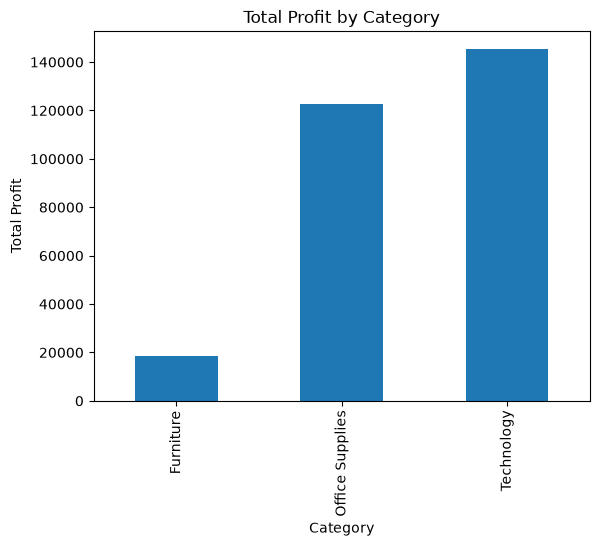

In [13]:
import matplotlib.pyplot as plt

category_profit.plot(kind="bar")

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.show()

In [14]:
##Analyze sales by region
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales.sort_values(ascending=False))

Region
West       725457.93
East       678781.36
Central    501239.88
South      391721.90
Name: Sales, dtype: float64


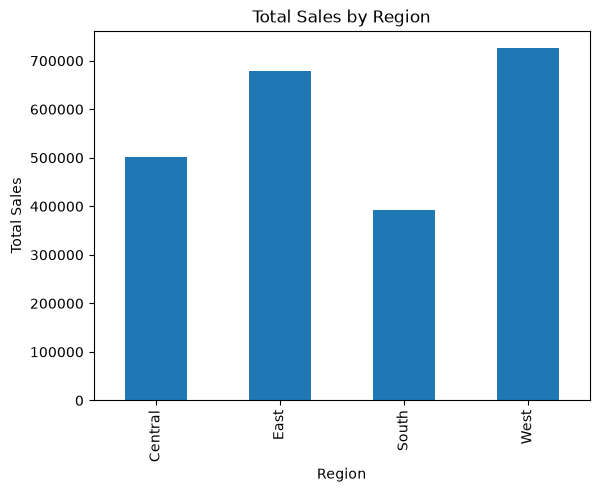

In [15]:
##Visualize regional sales

region_sales.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

In [16]:
##Calculate profit by region

region_profit = df.groupby("Region")["Profit"].sum()

print(region_profit.sort_values(ascending=False))

Region
West       108418.79
East        91522.84
South       46749.71
Central     39706.45
Name: Profit, dtype: float64


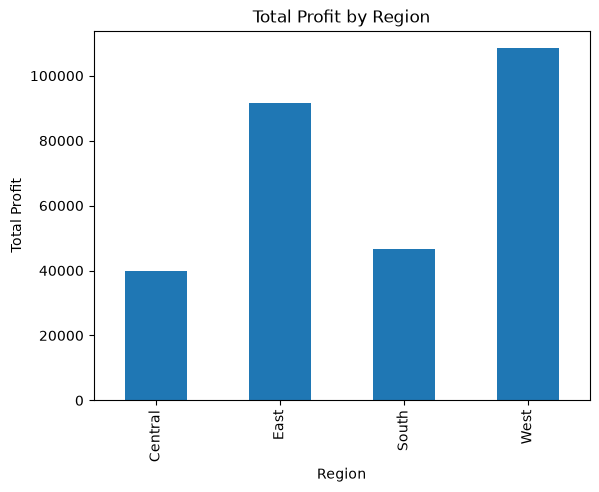

In [17]:
##Visualize regional profit
region_profit.plot(kind="bar")

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.show()


In [18]:
##Investigate the impact of discounts
discount_profit = df.groupby("Discount")["Profit"].mean()

print(discount_profit)


Discount
0.00     66.900350
0.10     96.055426
0.15     27.288077
0.20     24.702806
0.30    -45.679912
0.32    -88.561481
0.40   -111.927573
0.45   -226.647273
0.50   -310.704697
0.60    -43.077101
0.70    -95.874306
0.80   -101.797100
Name: Profit, dtype: float64


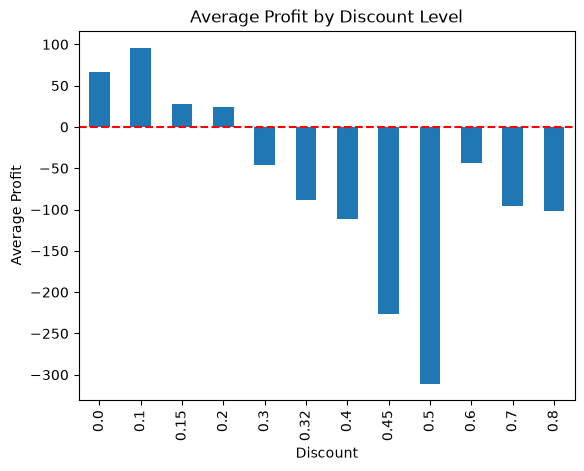

In [19]:
## Create a discount-profit chart

discount_profit.plot(kind="bar")

plt.title("Average Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.axhline(y=0, color="red", linestyle="--")
plt.show()

In [20]:
##Find the top 10 most profitable sub-categories

top_10_subcategories = subcategory_profit.head(10)

print(top_10_subcategories)

Sub_Category
Accessories    41936.78
Appliances     18138.07
Art             6527.96
Binders        30221.64
Bookcases      -3472.56
Chairs         26590.15
Copiers        55617.90
Envelopes       6964.10
Fasteners        949.53
Furnishings    13059.25
Name: Profit, dtype: float64


In [21]:
top_10_subcategories = (
    df.groupby("Sub_Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_10_subcategories)

Sub_Category
Copiers        55617.90
Phones         44516.25
Accessories    41936.78
Paper          34053.34
Binders        30221.64
Chairs         26590.15
Storage        21279.05
Appliances     18138.07
Furnishings    13059.25
Envelopes       6964.10
Name: Profit, dtype: float64


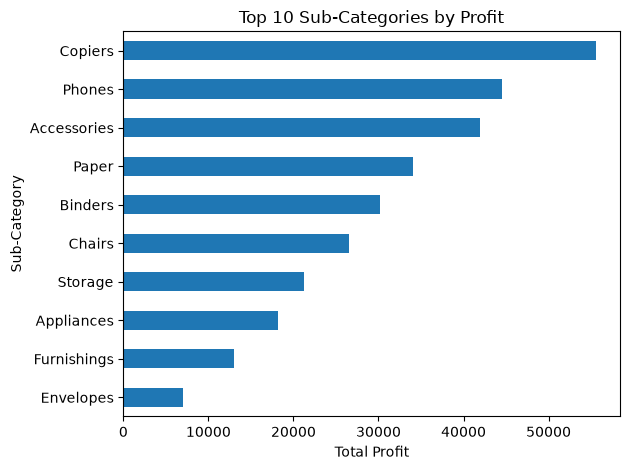

In [22]:
##Create a professional horizontal bar chart
top_10_subcategories.sort_values().plot(kind="barh")

plt.title("Top 10 Sub-Categories by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

In [23]:
##Check which categories generate losses
loss_subcategories = subcategory_profit[subcategory_profit < 0]

print(loss_subcategories)

Sub_Category
Bookcases    -3472.56
Supplies     -1188.99
Tables      -17725.59
Name: Profit, dtype: float64


In [24]:
##Calculate the total loss across these sub-categories

total_loss = loss_subcategories.sum()

print("Total Loss from Loss-Making Sub-Categories:", round(total_loss, 2))

Total Loss from Loss-Making Sub-Categories: -22387.14


In [25]:
##Save your analysis results
category_profit.to_csv("../data/category_profit.csv")

In [26]:
##Save your regional analysis too

region_summary = pd.DataFrame({
    "Total Sales": region_sales,
    "Total Profit": region_profit
})

region_summary.to_csv("../data/region_summary.csv")

region_summary

,Total Sales,Total Profit
Region,,
Central,501239.88,39706.45
East,678781.36,91522.84
South,391721.90,46749.71
West,725457.93,108418.79


In [27]:
import sqlite3

print("SQLite version:", sqlite3.sqlite_version)

SQLite version: 3.42.0


In [28]:
import sqlite3

connection = sqlite3.connect("../data/sales.db")

df.to_sql("superstore", connection, if_exists="replace", index=False)

print("Sales data loaded into SQLite successfully!")

Sales data loaded into SQLite successfully!


In [29]:
query = """
SELECT SUM(Sales) AS total_sales
FROM superstore;
"""

sql_result = pd.read_sql_query(query, connection)

print(sql_result)

   total_sales
0   2297201.07


In [30]:
##Calculate profit by category using SQL

query = """
SELECT
    Category,
    SUM(Profit) AS total_profit
FROM superstore
GROUP BY Category
ORDER BY total_profit DESC;
"""

category_sql = pd.read_sql_query(query, connection)

print(category_sql)

          Category  total_profit
0       Technology     145455.66
1  Office Supplies     122490.88
2        Furniture      18451.25


In [31]:
##Calculate sales by region using SQL
query = """
SELECT
    Region,
    SUM(Sales) AS total_sales
FROM superstore
GROUP BY Region
ORDER BY total_sales DESC;
"""

region_sql = pd.read_sql_query(query, connection)

print(region_sql)

    Region  total_sales
0     West    725457.93
1     East    678781.36
2  Central    501239.88
3    South    391721.90


In [32]:
##Find loss-making sub-categories using SQL
query = """
SELECT
    Sub_Category,
    SUM(Profit) AS total_profit
FROM superstore
GROUP BY Sub_Category
HAVING SUM(Profit) < 0
ORDER BY total_profit ASC;
"""

loss_sql = pd.read_sql_query(query, connection)

print(loss_sql)


  Sub_Category  total_profit
0       Tables     -17725.59
1    Bookcases      -3472.56
2     Supplies      -1188.99


In [33]:
##Calculate profit margin by category using SQL

query = """
SELECT
    Category,
    SUM(Sales) AS total_sales,
    SUM(Profit) AS total_profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS profit_margin_pct
FROM superstore
GROUP BY Category
ORDER BY profit_margin_pct DESC;
"""

margin_sql = pd.read_sql_query(query, connection)

print(margin_sql)

          Category  total_sales  total_profit  profit_margin_pct
0       Technology    836154.10     145455.66              17.40
1  Office Supplies    719046.99     122490.88              17.04
2        Furniture    741999.98      18451.25               2.49


In [37]:

import pandas as pd
import sqlite3

# Connect to the existing database
connection = sqlite3.connect("../data/sales.db")

# 1. Total sales and profit
query1 = """
SELECT
    SUM(Sales) AS total_sales,
    SUM(Profit) AS total_profit
FROM superstore;
"""

result1 = pd.read_sql_query(query1, connection)
print("1. Total Sales and Profit")
display(result1)


# 2. Profit by category
query2 = """
SELECT
    Category,
    SUM(Profit) AS total_profit
FROM superstore
GROUP BY Category
ORDER BY total_profit DESC;
"""

result2 = pd.read_sql_query(query2, connection)
print("2. Profit by Category")
display(result2)


# 3. Sales by region
query3 = """
SELECT
    Region,
    SUM(Sales) AS total_sales
FROM superstore
GROUP BY Region
ORDER BY total_sales DESC;
"""

result3 = pd.read_sql_query(query3, connection)
print("3. Sales by Region")
display(result3)


# 4. Loss-making sub-categories
query4 = """
SELECT
    Sub_Category,
    SUM(Profit) AS total_profit
FROM superstore
GROUP BY Sub_Category
HAVING SUM(Profit) < 0
ORDER BY total_profit ASC;
"""

result4 = pd.read_sql_query(query4, connection)
print("4. Loss-Making Sub-Categories")
display(result4)


# 5. Profit margin by category
query5 = """
SELECT
    Category,
    SUM(Sales) AS total_sales,
    SUM(Profit) AS total_profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2)
        AS profit_margin_pct
FROM superstore
GROUP BY Category
ORDER BY profit_margin_pct DESC;
"""

result5 = pd.read_sql_query(query5, connection)
print("5. Profit Margin by Category")
display(result5)


1. Total Sales and Profit


,total_sales,total_profit
0,2297201.07,286397.79


2. Profit by Category


,Category,total_profit
0,Technology,145455.66
1,Office Supplies,122490.88
2,Furniture,18451.25


3. Sales by Region


,Region,total_sales
0,West,725457.93
1,East,678781.36
2,Central,501239.88
3,South,391721.90


4. Loss-Making Sub-Categories


,Sub_Category,total_profit
0,Tables,-17725.59
1,Bookcases,-3472.56
2,Supplies,-1188.99


5. Profit Margin by Category


,Category,total_sales,total_profit,profit_margin_pct
0,Technology,836154.10,145455.66,17.40
1,Office Supplies,719046.99,122490.88,17.04
2,Furniture,741999.98,18451.25,2.49


In [38]:
import pandas as pd

df_full = pd.read_csv("../data/superstore_full.csv")

print("Dataset shape:", df_full.shape)
print("\nColumn names:")
print(df_full.columns.tolist())

display(df_full.head())

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,08/11/16,11/11/16,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,12/06/16,16/06/16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,11/10/15,18/10/15,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [39]:
##Check and convert the date columns
# Check the current data types
print(df_full[["Order Date", "Ship Date"]].dtypes)

# Convert both columns to datetime format
df_full["Order Date"] = pd.to_datetime(df_full["Order Date"])
df_full["Ship Date"] = pd.to_datetime(df_full["Ship Date"])

# Check the converted data types
print("\nAfter conversion:")
print(df_full[["Order Date", "Ship Date"]].dtypes)

# Display a few dates
display(df_full[["Order Date", "Ship Date"]].head())


Order Date    str
Ship Date     str
dtype: object


C:\Users\OMEN\AppData\Local\Temp\ipykernel_18268\1639724048.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_full["Order Date"] = pd.to_datetime(df_full["Order Date"])
C:\Users\OMEN\AppData\Local\Temp\ipykernel_18268\1639724048.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_full["Ship Date"] = pd.to_datetime(df_full["Ship Date"])



After conversion:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


,Order Date,Ship Date
0,2016-08-11,2016-11-11
1,2016-08-11,2016-11-11
2,2016-12-06,2016-06-16
3,2015-11-10,2015-10-18
4,2015-11-10,2015-10-18


In [40]:
# Check the earliest and latest order dates
print("Earliest order date:", df_full["Order Date"].min())
print("Latest order date:", df_full["Order Date"].max())

# Check whether any dates are missing
print("\nMissing order dates:", df_full["Order Date"].isna().sum())
print("Missing ship dates:", df_full["Ship Date"].isna().sum())

# Calculate shipping time in days
df_full["Shipping Days"] = (
    df_full["Ship Date"] - df_full["Order Date"]
).dt.days

# Show records with negative shipping times
print(
    "\nRecords with negative shipping days:",
    (df_full["Shipping Days"] < 0).sum()
)

# Display a few suspicious records
display(
    df_full.loc[
        df_full["Shipping Days"] < 0,
        ["Order ID", "Order Date", "Ship Date", "Shipping Days"]
    ].head(10)
)

Earliest order date: 2014-01-02 00:00:00
Latest order date: 2017-12-30 00:00:00

Missing order dates: 0
Missing ship dates: 0

Records with negative shipping days: 1708


,Order ID,Order Date,Ship Date,Shipping Days
2,CA-2016-138688,2016-12-06,2016-06-16,-173
3,US-2015-108966,2015-11-10,2015-10-18,-23
4,US-2015-108966,2015-11-10,2015-10-18,-23
5,CA-2014-115812,2014-09-06,2014-06-14,-84
6,CA-2014-115812,2014-09-06,2014-06-14,-84
7,CA-2014-115812,2014-09-06,2014-06-14,-84
8,CA-2014-115812,2014-09-06,2014-06-14,-84
9,CA-2014-115812,2014-09-06,2014-06-14,-84
10,CA-2014-115812,2014-09-06,2014-06-14,-84
11,CA-2014-115812,2014-09-06,2014-06-14,-84


In [41]:
##Reload the dates as text
# Reload the CSV without converting dates
df_check = pd.read_csv(
    "../data/superstore_full.csv",
    dtype={"Order Date": str, "Ship Date": str}
)

# Display the original date strings
display(
    df_check[["Order ID", "Order Date", "Ship Date"]].head(15)
)

,Order ID,Order Date,Ship Date
0,CA-2016-152156,08/11/16,11/11/16
1,CA-2016-152156,08/11/16,11/11/16
2,CA-2016-138688,12/06/16,16/06/16
3,US-2015-108966,11/10/15,18/10/15
4,US-2015-108966,11/10/15,18/10/15
5,CA-2014-115812,09/06/14,14/06/14
6,CA-2014-115812,09/06/14,14/06/14
7,CA-2014-115812,09/06/14,14/06/14
8,CA-2014-115812,09/06/14,14/06/14
9,CA-2014-115812,09/06/14,14/06/14


In [42]:
##Fix the date conversion
# Reload the dataset cleanly
df_full = pd.read_csv("../data/superstore_full.csv")

# Parse dates using the correct day/month/year format
df_full["Order Date"] = pd.to_datetime(
    df_full["Order Date"],
    format="%d/%m/%y"
)

df_full["Ship Date"] = pd.to_datetime(
    df_full["Ship Date"],
    format="%d/%m/%y"
)

# Calculate shipping time
df_full["Shipping Days"] = (
    df_full["Ship Date"] - df_full["Order Date"]
).dt.days

# Verify the results
print("Earliest order:", df_full["Order Date"].min())
print("Latest order:", df_full["Order Date"].max())
print("Missing order dates:", df_full["Order Date"].isna().sum())
print("Missing ship dates:", df_full["Ship Date"].isna().sum())
print(
    "Negative shipping times:",
    (df_full["Shipping Days"] < 0).sum()
)

display(
    df_full[["Order ID", "Order Date", "Ship Date", "Shipping Days"]].head(10)
)

Earliest order: 2014-01-03 00:00:00
Latest order: 2017-12-30 00:00:00
Missing order dates: 0
Missing ship dates: 0
Negative shipping times: 0


,Order ID,Order Date,Ship Date,Shipping Days
0,CA-2016-152156,2016-11-08,2016-11-11,3
1,CA-2016-152156,2016-11-08,2016-11-11,3
2,CA-2016-138688,2016-06-12,2016-06-16,4
3,US-2015-108966,2015-10-11,2015-10-18,7
4,US-2015-108966,2015-10-11,2015-10-18,7
5,CA-2014-115812,2014-06-09,2014-06-14,5
6,CA-2014-115812,2014-06-09,2014-06-14,5
7,CA-2014-115812,2014-06-09,2014-06-14,5
8,CA-2014-115812,2014-06-09,2014-06-14,5
9,CA-2014-115812,2014-06-09,2014-06-14,5


In [43]:
##Calculate monthly sales and profit

# Create a monthly period from each order date
df_full["Order Month"] = df_full["Order Date"].dt.to_period("M")

# Group the data by month and calculate sales and profit
monthly_summary = (
    df_full.groupby("Order Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

# Convert monthly periods into timestamps for charting
monthly_summary["Order Month"] = (
    monthly_summary["Order Month"].dt.to_timestamp()
)

# Display the first 12 months
display(monthly_summary.head(12))

,Order Month,Total_Sales,Total_Profit
0,2014-01-01,14236.8950,2450.1907
1,2014-02-01,4519.8920,862.3084
2,2014-03-01,55691.0090,498.7299
3,2014-04-01,28295.3450,3488.8352
4,2014-05-01,23648.2870,2738.7096
5,2014-06-01,34595.1276,4976.5244
6,2014-07-01,33946.3930,-841.4826
7,2014-08-01,27909.4685,5318.1050
8,2014-09-01,81777.3508,8328.0994
9,2014-10-01,31453.3930,3448.2573


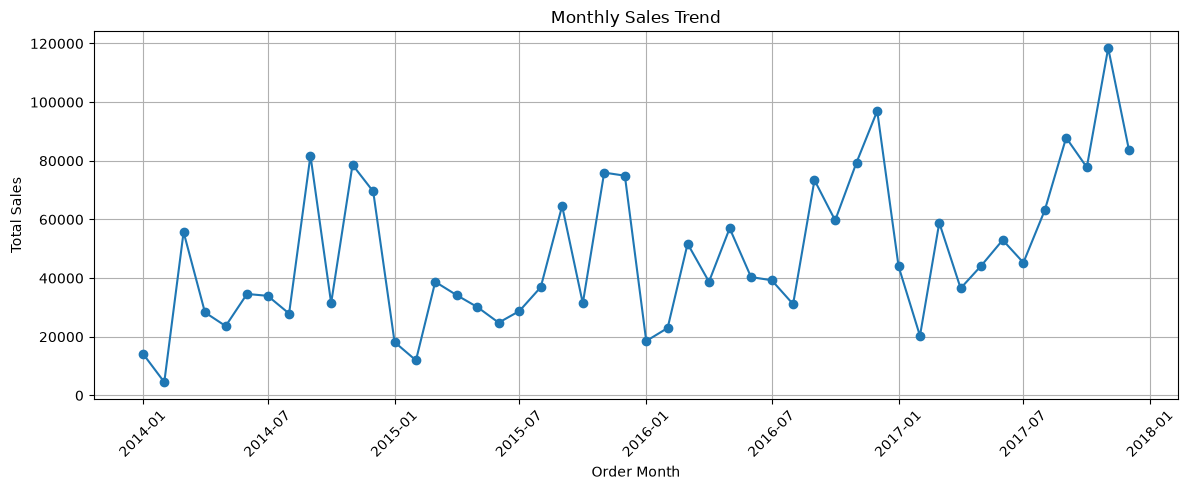

In [44]:
##Create your monthly sales trend chart

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_summary["Order Month"],
    monthly_summary["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Order Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

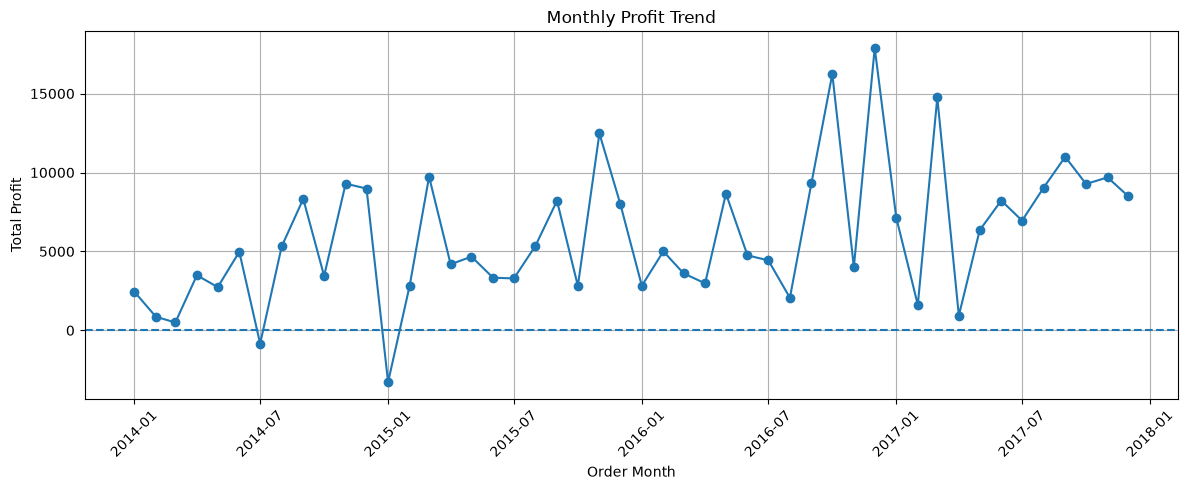

In [45]:
#Create a monthly profit trend chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_summary["Order Month"],
    monthly_summary["Total_Profit"],
    marker="o"
)

# Show the zero-profit line
plt.axhline(y=0, linestyle="--")

plt.title("Monthly Profit Trend")
plt.xlabel("Order Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [46]:
# Save the monthly summary as a CSV file
monthly_summary.to_csv(
    "../data/monthly_summary.csv",
    index=False
)

print("Monthly summary exported successfully!")

Monthly summary exported successfully!


In [48]:
# Create a separate copy for SQLite
df_sql = df_full.copy()

# Convert datetime columns to strings
df_sql["Order Date"] = df_sql["Order Date"].dt.strftime("%Y-%m-%d")
df_sql["Ship Date"] = df_sql["Ship Date"].dt.strftime("%Y-%m-%d")

# Convert the monthly Period column to strings
df_sql["Order Month"] = df_sql["Order Month"].astype(str)

# Update the database
df_sql.to_sql(
    "superstore",
    connection,
    if_exists="replace",
    index=False
)

print("Database updated successfully!")

# Verify the table columns
display(
    pd.read_sql_query(
        "PRAGMA table_info(superstore);",
        connection
    )
)

Database updated successfully!


,cid,name,type,notnull,dflt_value,pk
0,0,Row ID,INTEGER,0,None,0
1,1,Order ID,TEXT,0,None,0
2,2,Order Date,TEXT,0,None,0
3,3,Ship Date,TEXT,0,None,0
4,4,Ship Mode,TEXT,0,None,0
5,5,Customer ID,TEXT,0,None,0
6,6,Customer Name,TEXT,0,None,0
7,7,Segment,TEXT,0,None,0
8,8,Country,TEXT,0,None,0
9,9,City,TEXT,0,None,0
